In [2]:
import numpy as np
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
fashion_mnist=tf.keras.datasets.fashion_mnist


In [3]:
(X_train,y_train),(X_test,y_test)=fashion_mnist.load_data()

In [ ]:
print("Training shape:", X_train.shape)
print("Training shape:", y_train.shape)
print("Test images:", X_test.shape)
print("Test labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


In [5]:
X_train[3,10,1]

np.uint8(0)

In [6]:
X_train[3, 10]

array([  0,   0,   0,   0,   0,   0,   2,   0,  98, 171, 129, 112, 104,
       114, 106, 102, 112, 104, 133,  64,   0,   4,   0,   0,   0,   0,
         0,   0], dtype=uint8)

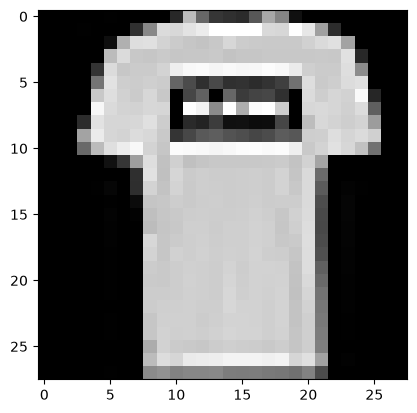

In [7]:
import matplotlib.pyplot as plt

plt.imshow(X_train[1], cmap="gray")
plt.show()

In [8]:
len(y_train)


60000

In [9]:
print(np.unique(y_train))

[0 1 2 3 4 5 6 7 8 9]


In [10]:
labels, counts = np.unique(y_train, return_counts=True)

for label, count in zip(labels, counts):
    print(f"Label {label}: {count} images")

Label 0: 6000 images
Label 1: 6000 images
Label 2: 6000 images
Label 3: 6000 images
Label 4: 6000 images
Label 5: 6000 images
Label 6: 6000 images
Label 7: 6000 images
Label 8: 6000 images
Label 9: 6000 images


In [11]:
X_train=X_train/255
X_test=X_test/255

In [12]:
X_train[3, 10]

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.00784314, 0.        , 0.38431373, 0.67058824,
       0.50588235, 0.43921569, 0.40784314, 0.44705882, 0.41568627,
       0.4       , 0.43921569, 0.40784314, 0.52156863, 0.25098039,
       0.        , 0.01568627, 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        ])

In [13]:
X_train=X_train.reshape(-1,28,28,1)
X_test=X_test.reshape(-1,28,28,1)

In [14]:
fashion_model=tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28,28,1)),
    tf.keras.layers.Conv2D(32,(3,3),activation="relu"),
    tf.keras.layers.MaxPool2D((2,2)),
    tf.keras.layers.Conv2D(64,(3,3),activation="relu"),
    tf.keras.layers.MaxPool2D((2,2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128,activation="relu"),
    tf.keras.layers.Dense(10,activation="softmax")
])


flatten_model = tf.keras.Model(
    inputs=fashion_model.inputs,
    outputs=fashion_model.layers[4].output
)

flatten_values = flatten_model.predict(X_train[0:1])

print(flatten_values.shape)
print(flatten_values)



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 193ms/step
(1, 1600)
[[3.0608360e-05 0.0000000e+00 0.0000000e+00 ... 1.0735961e-01
  9.7197197e-02 5.2100956e-02]]


In [15]:
fashion_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [16]:
fashion_model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step - accuracy: 0.8127 - loss: 0.5149 - val_accuracy: 0.8643 - val_loss: 0.3833
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.8761 - loss: 0.3422 - val_accuracy: 0.8832 - val_loss: 0.3269
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.8924 - loss: 0.2948 - val_accuracy: 0.8942 - val_loss: 0.2944
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.9050 - loss: 0.2616 - val_accuracy: 0.8971 - val_loss: 0.2888
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.9138 - loss: 0.2361 - val_accuracy: 0.9013 - val_loss: 0.2748
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - accuracy: 0.9218 - loss: 0.2133 - val_accuracy: 0.9064 - val_loss: 0.2574
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.9281 - loss: 0.1936 - val_accuracy: 0.9104 - val_loss: 0.2558
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.9351 - loss: 0.1748 - 

In [17]:
fashion_test_loss, fashion_test_accuracy = fashion_model.evaluate(
    X_test, y_test, verbose=0
)

In [18]:
print(f"Test loss: {fashion_test_loss:.4f}")
print(f"Test accuracy: {fashion_test_accuracy:.4f}")

Test loss: 0.2831
Test accuracy: 0.9059


In [23]:
fashion_probabilities = fashion_model.predict(X_test, verbose=0)
fashion_probabilities

array([[5.7195737e-10, 1.8019224e-09, 2.2894787e-08, ..., 1.5059841e-04,
        4.3034110e-09, 9.9983501e-01],
       [4.7022926e-08, 5.8536375e-12, 9.9997950e-01, ..., 2.1324608e-16,
        6.8484243e-13, 4.4826427e-14],
       [1.5684485e-07, 9.9999988e-01, 9.5387594e-11, ..., 6.7092175e-19,
        5.6539490e-13, 2.6329846e-20],
       ...,
       [7.5634332e-11, 1.2636239e-12, 1.1822627e-09, ..., 6.9498622e-13,
        1.0000000e+00, 4.8617298e-15],
       [3.5141756e-08, 9.9999976e-01, 3.2936082e-08, ..., 1.6753978e-14,
        1.0133544e-10, 4.6142455e-14],
       [1.1667106e-05, 9.9055806e-06, 2.4886906e-05, ..., 2.6620008e-02,
        5.2632727e-03, 4.6088975e-05]], shape=(10000, 10), dtype=float32)

In [24]:
fashion_predictions = np.argmax(fashion_probabilities, axis=1)
fashion_predictions


array([9, 2, 1, ..., 8, 1, 5], shape=(10000,))

In [27]:
fashion_cm = confusion_matrix(y_test, fashion_predictions)
fashion_cm

array([[810,   0,  19,   9,   3,   3, 144,   0,  12,   0],
       [  2, 978,   0,  14,   1,   0,   3,   0,   2,   0],
       [ 16,   0, 816,   4,  73,   0,  89,   0,   2,   0],
       [ 17,  11,  14, 875,  39,   0,  39,   0,   5,   0],
       [  1,   1,  22,  16, 891,   0,  66,   0,   3,   0],
       [  0,   0,   0,   0,   0, 980,   0,  16,   0,   4],
       [ 66,   1,  37,  17,  68,   0, 793,   0,  18,   0],
       [  0,   0,   0,   0,   0,  10,   0, 961,   0,  29],
       [  1,   0,   1,   4,   1,   1,   2,   4, 985,   1],
       [  0,   0,   0,   0,   0,   6,   1,  23,   0, 970]])

In [22]:
print(classification_report(
    y_test,

    fashion_predictions
))


              precision    recall  f1-score   support

           0       0.89      0.81      0.85      1000
           1       0.99      0.98      0.98      1000
           2       0.90      0.82      0.85      1000
           3       0.93      0.88      0.90      1000
           4       0.83      0.89      0.86      1000
           5       0.98      0.98      0.98      1000
           6       0.70      0.79      0.74      1000
           7       0.96      0.96      0.96      1000
           8       0.96      0.98      0.97      1000
           9       0.97      0.97      0.97      1000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000

